# **Morphological operations**

#### **1. What are morphological operations?**

Morphological operations are techniques that process images based on shapes. They are often used to remove noise, separate objects, and refine object boundaries in binary or grayscale images.

- They treat images as collections of shapes.

- Based on applying a small shape called structuring element to probe and transform the image.

- Useful for binary images but also applicable to grayscale.

#### **2. Erosion**

**What is erosion?**

- Erosion shrinks the foreground (white) regions in a binary image.

- It works by sliding a structuring element (small shape) over the image.

- For a pixel to remain white, all pixels under the structuring element must be white.

- This causes boundaries of objects to be eroded away, removing small isolated regions or noisy pixels.

**When to use erosion?**
- To remove small noise points or dots.
- To disconnect connected objects that barely touch.
- To shrink objects slightly for shape refinement.

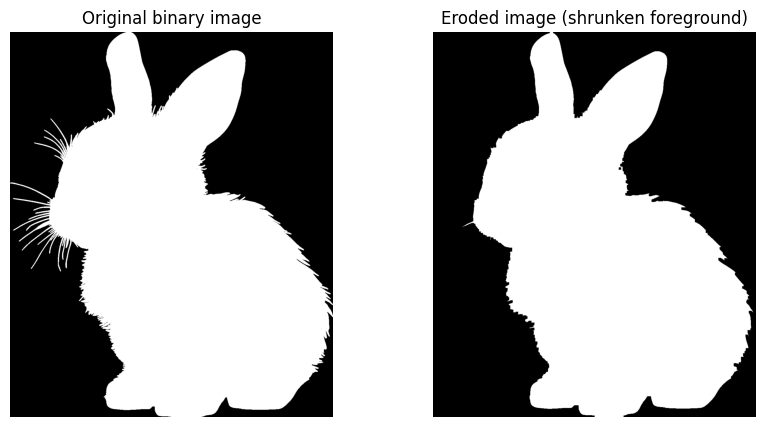

In [8]:
from skimage import data, morphology, color, io
import matplotlib.pyplot as plt

image = io.imread("bunny.jpg")
image_rgb = image[:, :, :3]
image_gray = color.rgb2gray(image_rgb)

# thresholding to get binary image
binary_img = image_gray > 0.5  

# structuring element: 8x8 rectangle (square)
selem = morphology.footprint_rectangle((8, 8))
eroded_img = morphology.erosion(binary_img, selem)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(binary_img, cmap='gray')
axes[0].set_title('Original binary image')
axes[1].imshow(eroded_img, cmap='gray')
axes[1].set_title('Eroded image (shrunken foreground)')

for ax in axes:
    ax.axis('off')
plt.show()


Footprints define the shape used in morphological operations like erosion and dilation. Common footprint types include:
- Rectangle

- Disk

- Diamond

- Ellipse

- Octagon

- Star

You can also create custom footprints using binary arrays to define any shape.

#### **3. Dilation**
What is Dilation?
- Dilation expands the foreground regions in a binary image.
- The structuring element slides over the image.
- If any pixel under the structuring element is white, the output pixel is set to white.
- This causes objects to grow in size, filling small holes and connecting close objects.

When to use dilation?
- Fill small holes or gaps inside objects.
- Connect nearby objects or regions.
- Expand shapes for emphasis.

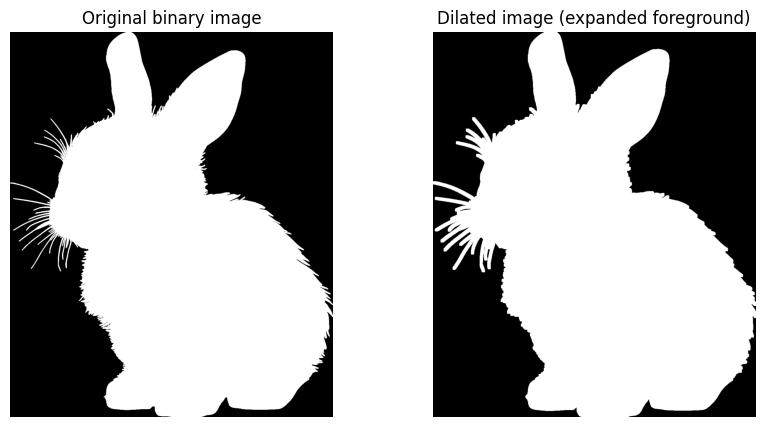

In [9]:
selem = morphology.footprint_rectangle((8, 8))

dilated_img = morphology.dilation(binary_img, selem)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(binary_img, cmap='gray')
axes[0].set_title('Original binary image')
axes[1].imshow(dilated_img, cmap='gray')
axes[1].set_title('Dilated image (expanded foreground)')

for ax in axes:
    ax.axis('off')
plt.show()


#### **4. Opening and closing**
Opening: Erosion followed by dilation.

- Removes small objects or noise while preserving shape and size of larger objects.

- Useful to clear tiny artifacts without significantly changing object size.

Closing: Dilation followed by erosion.

- Fills small holes or gaps inside objects.

- Useful to close small breaks or cavities in the foreground.

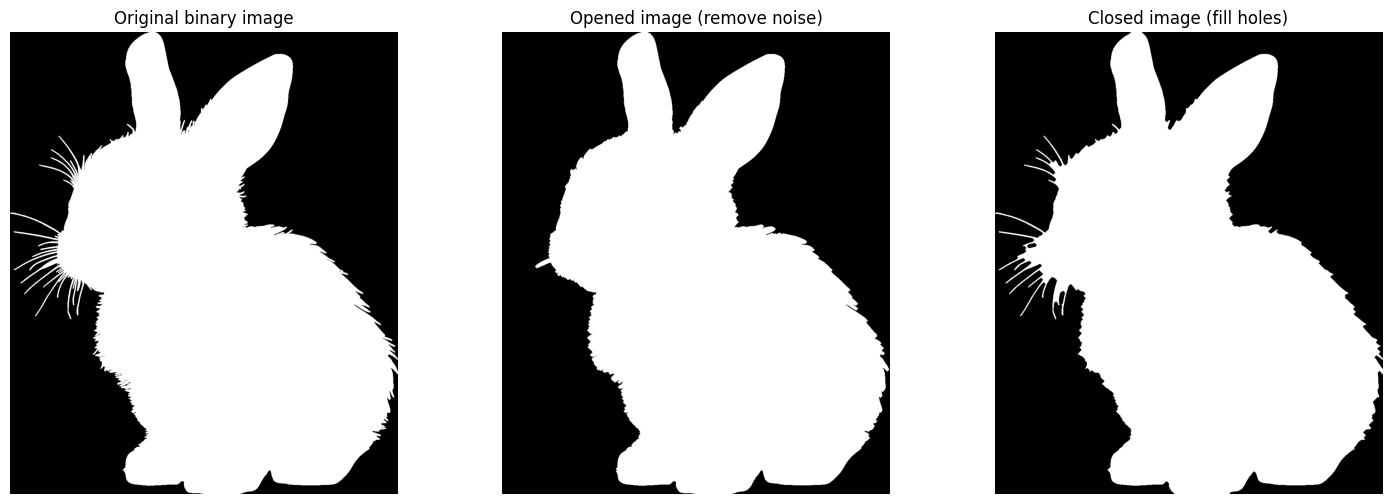

In [10]:
from skimage.morphology import opening, closing, diamond

selem = morphology.diamond(5)


opened_img = opening(binary_img, selem)
closed_img = closing(binary_img, selem)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(binary_img, cmap='gray')
axes[0].set_title('Original binary image')
axes[0].axis('off')
axes[1].imshow(opened_img, cmap='gray')
axes[1].set_title('Opened image (remove noise)')
axes[1].axis('off')
axes[2].imshow(closed_img, cmap='gray')
axes[2].set_title('Closed image (fill holes)')
axes[2].axis('off')
plt.show()


#### **5. Morphological gradient**

Defined as the difference between dilation and erosion of an image.
It highlights the edges of objects and emphasizes boundaries.

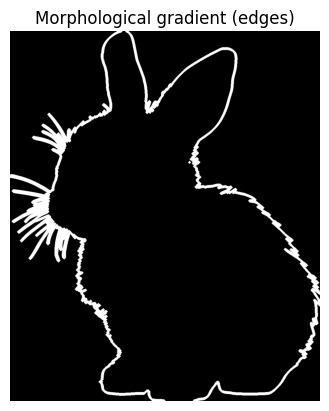

In [11]:
from skimage.morphology import dilation, erosion

gradient = dilation(binary_img, selem) ^ erosion(binary_img, selem)
plt.imshow(gradient, cmap='gray')
plt.title('Morphological gradient (edges)')
plt.axis('off')
plt.show()
